# To Perform an Analysis of Ensemble Technique

Krishna Jaiswal 21 C 

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier,
    AdaBoostClassifier, GradientBoostingClassifier,
    VotingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

sns.set_theme(style="whitegrid")

In [3]:
import os

In [4]:
os.getcwd()

'c:\\Users\\Krishna\\Desktop\\ML Final'

In [5]:
os.chdir('c:\\Users\\Krishna\\Desktop')

In [6]:
df=pd.read_csv("heart.csv")

df = df.drop_duplicates().dropna().reset_index(drop=True)

print("Dataset shape:", df.shape)
display(df.head())
print(df["target"].value_counts())

Dataset shape: (302, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


target
1    164
0    138
Name: count, dtype: int64


# Visualize Target Distribution

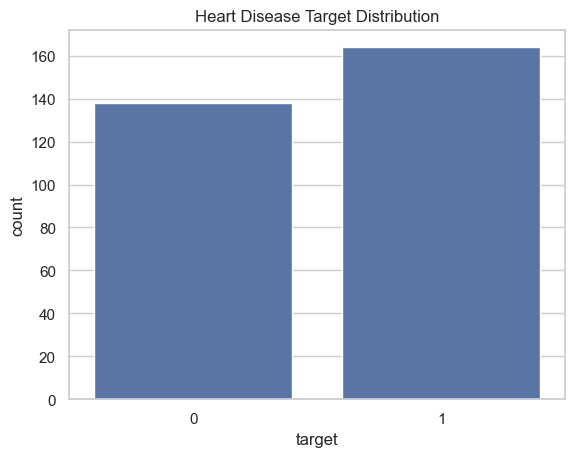

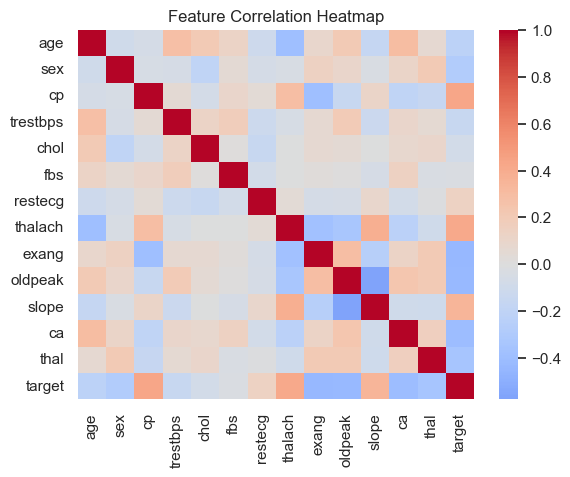

In [7]:
sns.countplot(data=df, x="target")
plt.title("Heart Disease Target Distribution")
plt.show()

sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

# Split and prepare the data

In [8]:
X = df.drop(columns="target")
y = df["target"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 241
Testing samples: 61


# Define Ensemble Models

In [9]:
models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=42
    ),
    "Voting": VotingClassifier(
        estimators=[
            ("lr", make_pipeline(StandardScaler(),
                                 LogisticRegression(max_iter=1000))),
            ("knn", make_pipeline(StandardScaler(),
                                  KNeighborsClassifier(n_neighbors=5))),
            ("rf", RandomForestClassifier(n_estimators=100,
                                          random_state=42))
        ],
        voting="soft"
    )
}

print("Ensemble models ready:", list(models.keys()))

Ensemble models ready: ['Bagging', 'Random Forest', 'AdaBoost', 'Gradient Boosting', 'Voting']


# Train and evaluate all models

In [10]:
results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Bagging,0.770,0.771,0.818,0.794,0.837
Random Forest,0.754,0.765,0.788,0.776,0.861
AdaBoost,0.738,0.793,0.697,0.742,0.869
Gradient Boosting,0.721,0.735,0.758,0.746,0.826
Voting,0.803,0.800,0.848,0.824,0.878


# Compare model performance

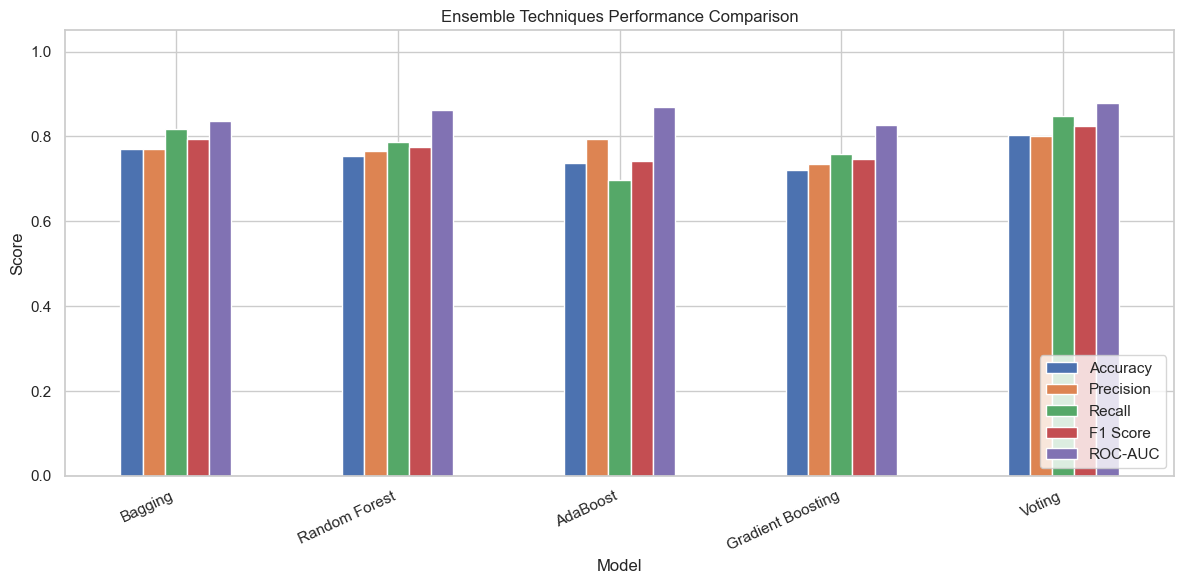

In [11]:
results_df[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 6)
)

plt.title("Ensemble Techniques Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Plot confusion matrices

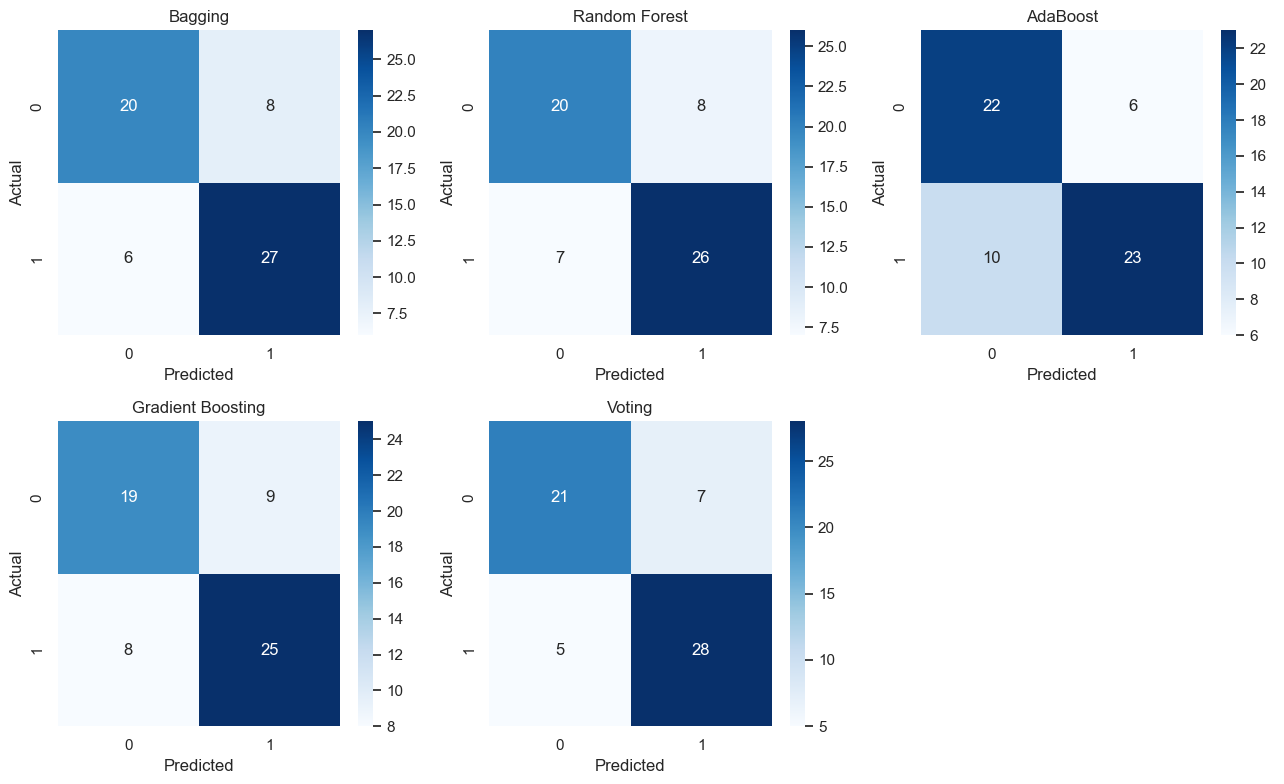

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):
    pred = model.predict(X_test)
    sns.heatmap(
        confusion_matrix(y_test, pred),
        annot=True, fmt="d", cmap="Blues", ax=axes[i]
    )
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

# Random Forest feature importance

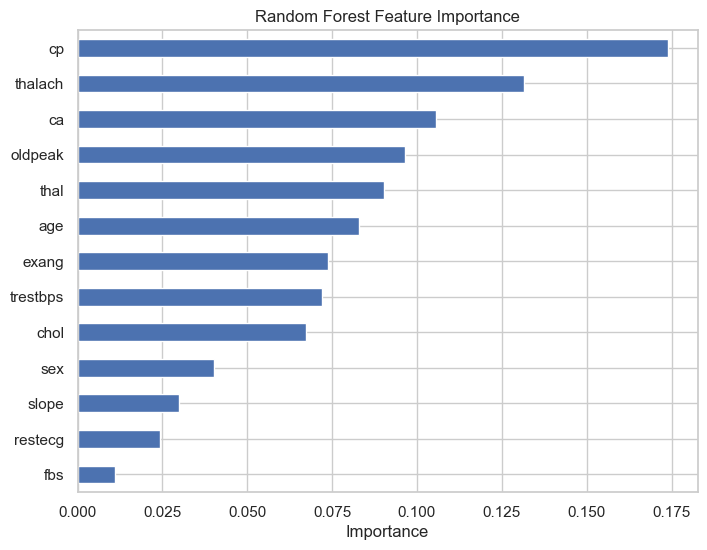

In [13]:
importance = pd.Series(
    trained_models["Random Forest"].feature_importances_,
    index=X.columns
).sort_values()

importance.plot(kind="barh", figsize=(8, 6))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

# Display the best-performing model

In [14]:
best_model = results_df["F1 Score"].idxmax()

print("Best model by F1 Score:", best_model)
print(results_df.loc[best_model].round(3))

Best model by F1 Score: Voting
Accuracy     0.803
Precision    0.800
Recall       0.848
F1 Score     0.824
ROC-AUC      0.878
Name: Voting, dtype: float64
